In [2]:
import numpy as np
import random
import seaborn as sns
from matplotlib import pyplot as plt
from shapely.geometry import Polygon
import splines
import pyclipr
from typing import Literal
from tqdm import tqdm
import numba

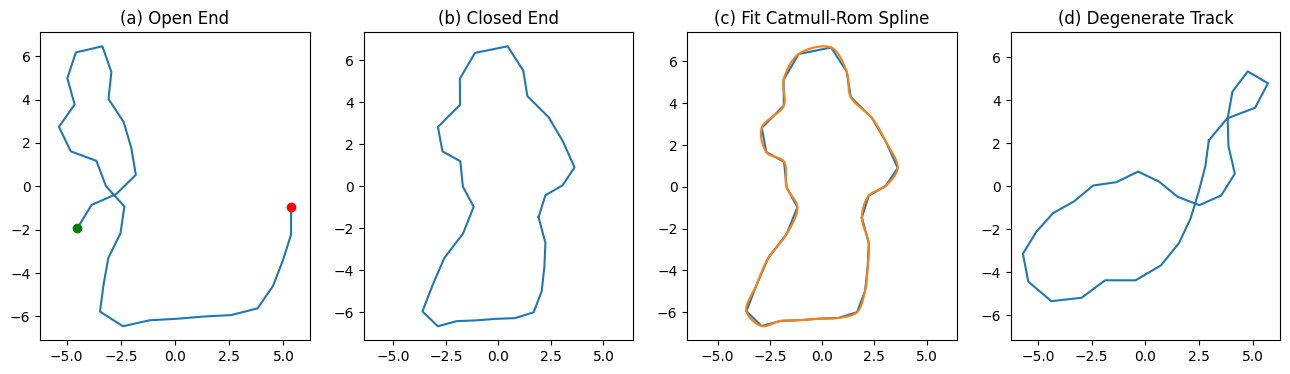

In [6]:
n = 30
radius = 6
max_turn_deg = 80
turn_restoring = 0.15
max_offset_deg = 90
closing_sharpness = 3

def generate_walk(
        n: int, 
        radius: float,
        max_turn_deg: float,
        turn_restoring: float,
        closing_sharpness: float,
        max_offset_deg: float,
        seed: int = 1,
        close_end: bool = True,
        spline: bool = False
):
    np.random.seed(seed)
    step = 2 * np.pi * radius / n
    pos = np.zeros((n + 1, 2))
    pos[0] = [radius, 0]
    offset = 0.0

    for i in range(n):
        progress = (i + 1) / n
        reference_heading = 2 * np.pi * progress + np.pi / 2
        restoring = turn_restoring + \
            (1 - turn_restoring) * progress ** closing_sharpness

        offset += np.radians(np.random.uniform(-max_turn_deg, max_turn_deg))
        offset -= restoring * offset
        offset = np.clip(offset, -np.radians(max_offset_deg),
                         np.radians(max_offset_deg))

        heading = reference_heading + offset
        pos[i + 1] = pos[i] + step * \
            np.array([np.cos(heading), np.sin(heading)])
    

    if close_end:
        diff = pos[0] - pos[-1]
        pos += diff * np.linspace(0, 1, n + 1)[:, np.newaxis]

    center = (pos.min(0) + pos.max(0)) / 2

    pos -= center

    if spline:
        curve = splines.CatmullRom(pos[:-1, :], alpha=0.5, endconditions='closed')
        t = np.linspace(curve.grid[0], curve.grid[-1], 500)
        spline = curve.evaluate(t)
        return spline
    return pos

def make_inset_and_outset(track: np.ndarray, inset: float, kind: Literal["clipper2", "mult", "additive"]):
    if kind == "clipper2":
        po = pyclipr.ClipperOffset()
        po.addPath(track, pyclipr.JoinType.Miter, pyclipr.EndType.Joined)
        clip_outset, clip_inset = po.execute(inset)
    elif kind == "mult":
        clip_inset = track * (1 - inset)
        clip_outset = track * 1/(1 - inset)
    elif kind == "additive":
        dir = track / np.linalg.norm(track, axis=1)[:, np.newaxis]
        clip_inset = track - dir * inset
        clip_outset = track + dir * inset
    else:
        raise ValueError(f"Unknown kind: {kind}")

    return clip_inset, clip_outset

SEED = 11
pos = generate_walk(n, radius, max_turn_deg, turn_restoring, closing_sharpness, max_offset_deg, seed=SEED, close_end=False)
pos_close_end = generate_walk(n, radius, max_turn_deg, turn_restoring, closing_sharpness, max_offset_deg, seed=SEED, close_end=True)
degenerate_track = generate_walk(n, radius, max_turn_deg, turn_restoring, closing_sharpness, max_offset_deg, seed=988916, close_end=True)

fig, axs = plt.subplots(1, 4, figsize=(16, 4))

axs[0].plot(pos[:, 0], pos[:, 1])
axs[0].set_title("(a) Open End")
axs[0].plot(pos[0, 0], pos[0, 1], 'go', label='Start')
axs[0].plot(pos[-1, 0], pos[-1, 1], 'ro', label='End')


axs[1].plot(pos_close_end[:, 0], pos_close_end[:, 1])
axs[1].set_title("(b) Closed End")


# fit a spline

spline = generate_walk(n, radius, max_turn_deg, turn_restoring, closing_sharpness, max_offset_deg, seed=SEED, close_end=True, spline=True)

axs[2].plot(pos_close_end[:, 0], pos_close_end[:, 1])
axs[2].plot(spline[:, 0], spline[:, 1])
axs[2].set_title("(c) Fit Catmull-Rom Spline")

axs[3].plot(degenerate_track[:, 0], degenerate_track[:, 1])
axs[3].set_title("(d) Degenerate Track")

for i in range(4):
    axs[i].axis('equal')
plt.savefig("results/figures/trackgen_walk.pdf")

In [103]:
tracks = [generate_walk(n, radius, max_turn_deg, turn_restoring, closing_sharpness, max_offset_deg, seed=i) for i in range(100_000)]
tracks = [Polygon(track) for track in tracks]
invalid_tracks = [track for track in tracks if not track.is_valid]
len(invalid_tracks)

50

In [ ]:
tracks = [generate_walk(n, radius, max_turn_deg, turn_restoring, closing_sharpness, max_offset_deg, seed=i, spline=True) for i in tqdm(range(100_000))]

100%|██████████| 100000/100000 [00:53<00:00, 1884.23it/s]


In [121]:
def is_valid_track(track: np.ndarray) -> bool:
    po = pyclipr.ClipperOffset()
    po.addPath(track, pyclipr.JoinType.Miter, pyclipr.EndType.Joined)
    insets = po.execute(0.7)
    return len(insets) == 2


is_valid_tracks = [is_valid_track(track) for track in tqdm(tracks)]

100%|██████████| 100000/100000 [01:11<00:00, 1407.03it/s]


In [123]:
is_valid_tracks.count(False)

1350

In [99]:
np.arange(len(tracks))[np.array([not track.is_valid for track in tracks])]

array([], dtype=int64)

In [1]:
from scipy.stats import beta, binomtest

x = 50
N = 100_000
# built in
ci = binomtest(x, N).proportion_ci(confidence_level=0.95, method="exact")
(ci.low, ci.high)

(0.0003711317017852701, 0.0006591351958566029)

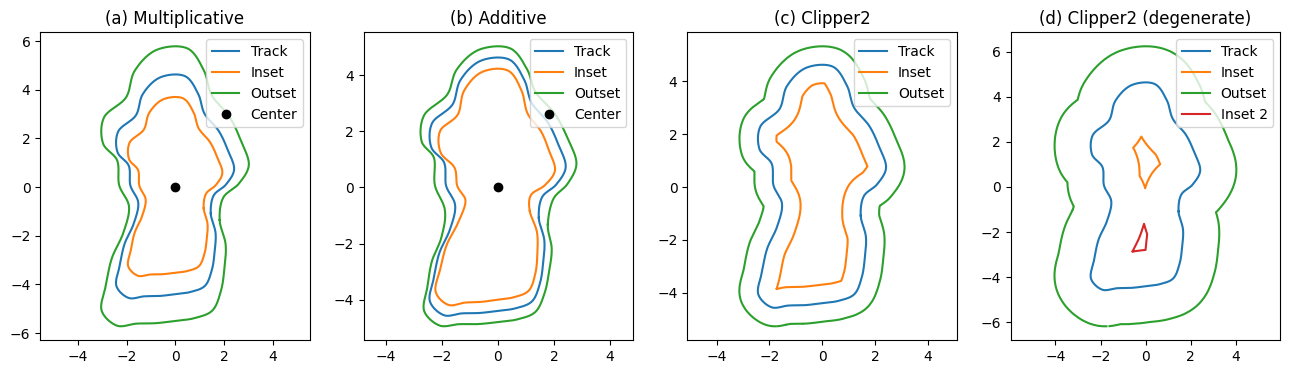

In [12]:
SEED = 11
track = generate_walk(30, 4, 60, 0.1, 3, 80, seed=SEED, close_end=True, spline=True)
inset_clipper, outset_clipper = make_inset_and_outset(track, 0.7, kind="clipper2")
inset_mult, outset_mult = make_inset_and_outset(track, 0.2, kind="mult")
inset_additive, outset_additive = make_inset_and_outset(track, 0.4, kind="additive")

fig, axs = plt.subplots(1, 4, figsize=(16, 4))

axs[0].plot(track[:, 0], track[:, 1], label="Track")
axs[0].plot(inset_mult[:, 0], inset_mult[:, 1], label="Inset")
axs[0].plot(outset_mult[:, 0], outset_mult[:, 1], label="Outset")
axs[0].plot(0, 0, 'ko', label='Center')
axs[0].set_title("(a) Multiplicative")
axs[0].axis('equal')
axs[0].legend()

axs[1].plot(track[:, 0], track[:, 1], label="Track")
axs[1].plot(inset_additive[:, 0], inset_additive[:, 1], label="Inset")
axs[1].plot(outset_additive[:, 0], outset_additive[:, 1], label="Outset")
axs[1].plot(0, 0, 'ko', label='Center')
axs[1].set_title("(b) Additive")
axs[1].axis('equal')
axs[1].legend()

axs[2].plot(track[:, 0], track[:, 1], label="Track")
axs[2].plot(inset_clipper[:, 0], inset_clipper[:, 1], label="Inset")
axs[2].plot(outset_clipper[:, 0], outset_clipper[:, 1], label="Outset")
axs[2].set_title("(c) Clipper2")
axs[2].axis('equal')
axs[2].legend(loc="upper right")



po = pyclipr.ClipperOffset()
po.addPath(track, pyclipr.JoinType.Miter, pyclipr.EndType.Joined)
clip_outset, clip_inset, clip_inset_2 = po.execute(1.6)


axs[3].plot(track[:, 0], track[:, 1], label="Track")
axs[3].plot(clip_inset[:, 0], clip_inset[:, 1], label="Inset")
axs[3].plot(clip_outset[:, 0], clip_outset[:, 1], label="Outset")
axs[3].plot(clip_inset_2[:, 0], clip_inset_2[:, 1], label="Inset 2")
axs[3].set_title("(d) Clipper2 (degenerate)")
axs[3].axis('equal')
axs[3].legend()

plt.savefig("results/figures/trackgen_inset_outset.pdf")

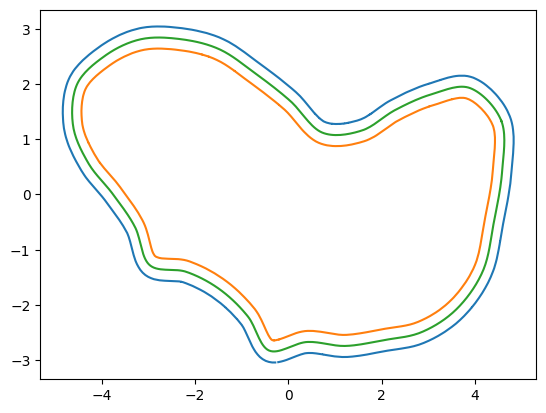

In [38]:

po = pyclipr.ClipperOffset()
po.addPath(track, pyclipr.JoinType.Miter, pyclipr.EndType.Polygon)
clip_inset = po.execute(0.2)[0]
clip_outset = po.execute(-0.2)[0]

plt.plot(clip_inset[:, 0], clip_inset[:, 1], label="Inset (pyclipr)")
plt.plot(clip_outset[:, 0], clip_outset[:, 1], label="Outset (pyclipr)")
plt.plot(track[:, 0], track[:, 1], label="Centerline (pyclipr)")

In [60]:
po = pyclipr.ClipperOffset()
po.addPath(track, pyclipr.JoinType.Miter, pyclipr.EndType.Joined)
clip_outset = po.execute(0.1)
clip_outset

[array([[-1.725, -4.677],
        [-1.675, -4.671],
        [-1.628, -4.662],
        ...,
        [-1.872, -4.674],
        [-1.821, -4.679],
        [-1.773, -4.679]], shape=(528, 2)),
 array([[-1.806e+00, -4.479e+00],
        [-1.846e+00, -4.475e+00],
        [-1.866e+00, -4.470e+00],
        [-1.893e+00, -4.462e+00],
        [-1.932e+00, -4.445e+00],
        [-1.961e+00, -4.431e+00],
        [-2.001e+00, -4.408e+00],
        [-2.036e+00, -4.386e+00],
        [-2.068e+00, -4.363e+00],
        [-2.103e+00, -4.336e+00],
        [-2.135e+00, -4.308e+00],
        [-2.170e+00, -4.274e+00],
        [-2.202e+00, -4.241e+00],
        [-2.230e+00, -4.209e+00],
        [-2.256e+00, -4.175e+00],
        [-2.275e+00, -4.146e+00],
        [-2.298e+00, -4.107e+00],
        [-2.310e+00, -4.083e+00],
        [-2.322e+00, -4.052e+00],
        [-2.333e+00, -4.011e+00],
        [-2.338e+00, -3.978e+00],
        [-2.340e+00, -3.942e+00],
        [-2.339e+00, -3.911e+00],
        [-2.335e+00, -3.863e+00